# 00 · Dataset exploration (Member 4: chatbot)

What the chatbot is trained on: the knowledge-base passages and the bilingual question dataset.
Reads only the CSV files in `data/` (made by `python -m member4_chatbot.pipeline.export_notebook_data`).
How every part was made is described in `../data/training/DATASET.md`.

In [ ]:
from pathlib import Path

HERE = Path.cwd()
DATA = HERE / "data"                                   # CSVs exported by member4_chatbot.pipeline.export_notebook_data
IN_REPO = (HERE.parent / "member4_chatbot").exists()   # False in Colab
ARTIFACTS = (HERE.parent / "artifacts") if IN_REPO else (HERE / "artifacts")
CHROMA = (HERE.parent / "data" / "chroma") if IN_REPO else (HERE / "chroma")
print("data:", DATA.resolve(), "| artifacts:", ARTIFACTS.resolve())

data: E:\soilmind\backend\member4-chatbot\notebooks\data | artifacts: E:\soilmind\backend\member4-chatbot\artifacts


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
intents = pd.read_csv(DATA / "intents.csv", keep_default_na=False)
qa = pd.read_csv(DATA / "qa_pairs.csv", keep_default_na=False)
oos = pd.read_csv(DATA / "out_of_scope.csv", keep_default_na=False)
passages = pd.read_csv(DATA / "passages.csv", keep_default_na=False)
log = pd.read_csv(DATA / "extraction_log.csv", keep_default_na=False)
print(f"{len(intents)} questions, {len(qa)} question-passage pairs, {len(oos)} out-of-scope, {len(passages)} passages")

2265 questions, 1366 question-passage pairs, 326 out-of-scope, 546 passages


## 1. The knowledge base
Documents were downloaded from doa.gov.lk (RRDI web pages, RRDI books and leaflets, NAICC leaflets and crop
calendars). Each document's text was extracted with the method in the log below.

In [ ]:
log.groupby("method").agg(documents=("doc", "count"), passages=("passages", "sum")).sort_values("documents", ascending=False)

,documents,passages
method,,
html_text,196,289
skipped_needs_ocr,35,0
text_layer,2,251
manual_text,1,6


In [ ]:
need_ocr = log[log.method == "skipped_needs_ocr"][["doc", "language", "note"]]
print(f"{len(need_ocr)} scanned documents are waiting for OCR (Tesseract with Sinhala data):")
need_ocr

35 scanned documents are waiting for OCR (Tesseract with Sinhala data):


,doc,language,note
15,rrdi_book_b1,unknown,Tesseract not installed
18,rrdi_book_b4_fert2013_si,si,Tesseract not installed
19,rrdi_leaf_weed_management_si,si,Tesseract not installed
20,rrdi_leaf_competitive_weeds_si,si,Tesseract not installed
21,rrdi_leaf_weedicides_si,si,Tesseract not installed
22,rrdi_leaf_water_management_si,si,Tesseract not installed
23,rrdi_leaf_rice_diseases_si,si,Tesseract not installed
24,rrdi_leaf_awd_si,si,Tesseract not installed
25,rrdi_leaf_weedy_rice_control_si,si,Tesseract not installed
26,rrdi_leaf_weedy_rice_identify_si,si,Tesseract not installed


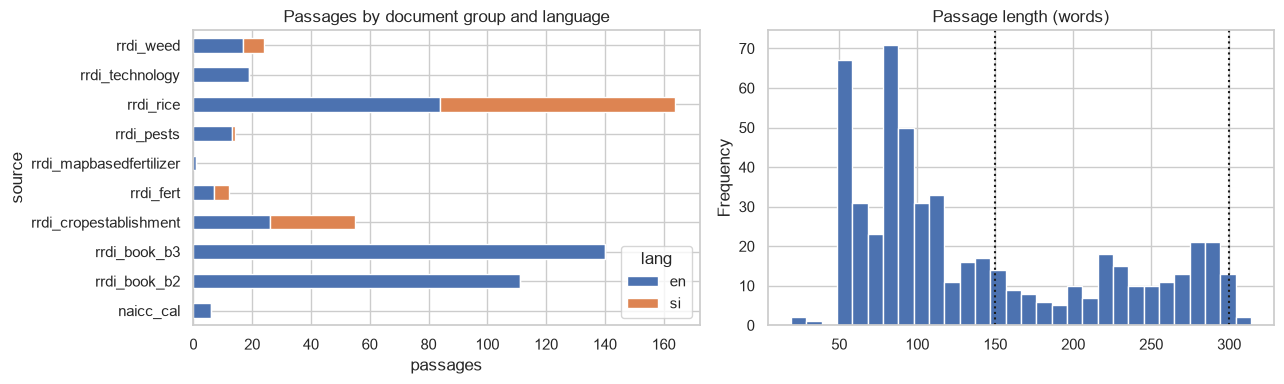

,count,mean,std,min,25%,50%,75%,max
lang,,,,,,,,
en,424.0,149.0,83.0,24.0,83.0,109.0,227.0,314.0
si,122.0,108.0,54.0,19.0,66.0,104.0,133.0,280.0


In [ ]:
passages["source"] = passages.doc.str.extract(r"^(rrdi_book_b\d|rrdi_fert|rrdi_rice|rrdi_pests|rrdi_ricediseases|rrdi_weed|rrdi_cropestablishment|rrdi_technology|naicc_cal|rrdi_[a-z]+)")[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
passages.groupby(["source", "lang"]).size().unstack(fill_value=0).plot.barh(stacked=True, ax=ax[0])
ax[0].set_title("Passages by document group and language"); ax[0].set_xlabel("passages")
passages.n_words.plot.hist(bins=30, ax=ax[1]); ax[1].set_title("Passage length (words)"); ax[1].axvline(150, c="k", ls=":"); ax[1].axvline(300, c="k", ls=":")
plt.tight_layout(); plt.show()
passages.groupby("lang").n_words.describe().round(0)

An example passage of each language:

In [ ]:
for lang in ("en", "si"):
    r = passages[(passages.lang == lang) & passages.doc.str.startswith("rrdi_fert")].iloc[0]
    print(f"--- {r.id} ({r.lang}, page {r.page}, {r.n_words} words)\n{r.text}\n")

--- rrdi_fert_irrigated_izdz_en__000 (en, page 1, 259 words)
Intermediate Zone and Dry zone (for paddy fields cultivated under irrigated conditions)
Districts and areas applicable Anuradhapura, Polonnaruwa, Monaragala, Hambantota, Mulatiw, Jaffna, Kurunegala, Mannar, Puttlm, Trincomalee, Kilinochchii, Badulla Kandy ( For Minipe, Ududumbara, Panwila, Medadumbara, Kundasale, Pathahewaheta, Delthota divisional secretariats) Nuwara Eliya ( For Hanguranketha, Walapane divisional secretariats) Rathnapura ( For Embilipitiya, Kolonna, Balangoda, Imbulpe, Weligepola divisional secretariats) Mathara ( For Hakmana, Kirinda, Devinuwara, Dikwella, Thihagoda, Kamburupitiya divisional secretariats) Mathale ( Except Yatawattha, Ukuwela divisional secretariats)
Age Group | Time * | Urea | T.S.P | M.O.P | Zinc Sulphate
Kg/Ha
For 3 Month | Basic | | 55 | | 5
2 Weeks | 50 | | |
4 Weeks | 75 | | 25 |
6 Weeks | 65 | | 35 |
7 Weeks | 35 | | |
Total | 225 | 55 | 60 | 5
For 3 1/2 Month | Basic | | 55 | | 5
2 W

## 2. Questions per intent, language and split

In [ ]:
t = intents.pivot_table(index="intent", columns="lang", values="id", aggfunc="count", fill_value=0)
t["total"] = t.sum(axis=1)
t.join(intents.pivot_table(index="intent", columns="split", values="id", aggfunc="count", fill_value=0)).sort_values("total")

,en,si,si_latn,total,test,train,val
intent,,,,,,,
weeds,55,37,1,93,12,66,15
water_management,53,42,0,95,12,71,12
greeting_help,47,53,5,105,16,73,16
deficiency_symptom,58,56,2,116,17,82,17
liming_ph,63,51,2,116,17,78,21
fertilizer_timing,60,60,0,120,19,85,16
my_field_status,64,60,5,129,19,89,21
crop_establishment,102,93,1,196,36,141,19
pest_disease,139,94,2,235,33,155,47


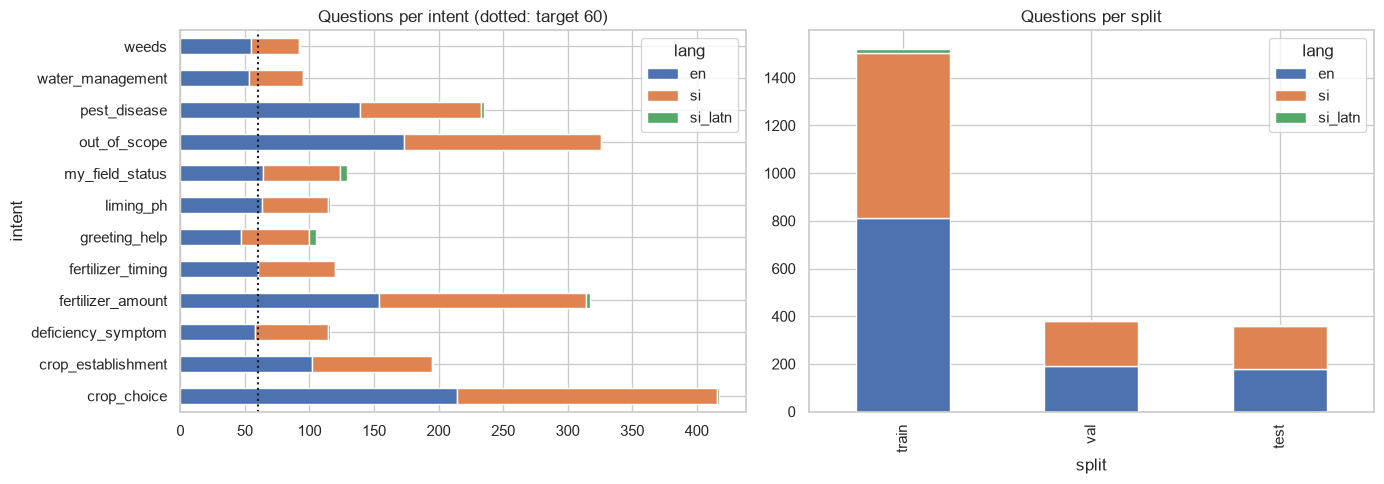

Sinhala script: 46.8% of all questions (target at least 40%); with Singlish: 47.8%


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
intents.groupby(["intent", "lang"]).size().unstack(fill_value=0).plot.barh(stacked=True, ax=ax[0])
ax[0].axvline(60, c="k", ls=":"); ax[0].set_title("Questions per intent (dotted: target 60)")
intents.groupby(["split", "lang"]).size().unstack(fill_value=0).loc[["train", "val", "test"]].plot.bar(stacked=True, ax=ax[1])
ax[1].set_title("Questions per split"); plt.tight_layout(); plt.show()
si_share = (intents.lang == "si").mean()
print(f"Sinhala script: {si_share:.1%} of all questions (target at least 40%); with Singlish: {intents.lang.isin(['si', 'si_latn']).mean():.1%}")

## 3. How the questions were made
**No question was written or checked by a person.** The `source` column says how each row was made:
- `auto_template`: generated by code from the RRDI tables, variety sheets and the crop calendar (exact numbers)
- `ai_drafted`: drafted by the AI coding assistant (Claude Code) from the passages
- `auto_paraphrase`: rule-based rewording (code) of an AI-drafted English question
- `machine_translated`: English → Sinhala with NLLB-200 (local)

In [ ]:
intents.pivot_table(index="source", columns="lang", values="id", aggfunc="count", fill_value=0).assign(total=lambda d: d.sum(axis=1))

lang,en,si,si_latn,total
source,,,,
ai_drafted,471,250,22,743
auto_paraphrase,360,0,0,360
auto_template,351,344,0,695
machine_translated,0,467,0,467


In [ ]:
for src in ["auto_template", "ai_drafted", "auto_paraphrase", "machine_translated"]:
    print(f"--- {src}")
    for _, r in intents[intents.source == src].sample(3, random_state=1).iterrows():
        print(f"  [{r.lang}] {r.intent:<18} {r.text}")

--- auto_template
  [si] crop_choice        Bg 300 හඳුන්වා දුන්නේ කවදද?
  [en] crop_choice        Can I grow At 311 in my area - where is it recommended?
  [en] fertilizer_amount  Wet Zone, irrigated paddy, 3 month variety: how many kg of urea at 6 weeks after establishment?
--- ai_drafted
  [si] crop_establishment කොච්චර ගැඹුරට හාන්න ඕනද?
  [si_latn] greeting_help      bohoma sthuthi
  [si] water_management   යල කන්නයේ වතුර ඉතිරි කරගන්නේ කොහොමද?
--- auto_paraphrase
  [en] water_management   Excuse me, what water level is needed at flowering?
  [en] out_of_scope       Explain a good diet for high blood pressure?
  [en] water_management   What do you advise in a drought season? Thanks.
--- machine_translated
  [si] deficiency_symptom මගේ රයිස් එකේ ටිලර් ටිකයි තද කොළ පැහැති කොළ ටිකයි තියෙනවා, ඒක ෆොස්පෝරස්ද?
  [si] out_of_scope       කෙතරම් දුරකට වක්කර පැලෑටි පිහිටා තිබේද?
  [si] deficiency_symptom මම කොහොමද සින්ක් හිඟය නිවැරදි කරන්නේ?


Question–answer pairs: an AI-drafted one, its paraphrase and its machine translation share one `group_id`, so they are always in the same split:

In [ ]:
g = qa[qa.source == "machine_translated"].group_id.iloc[0]
qa[qa.group_id == g][["source", "lang", "question", "answer", "passage_id", "split"]].head(6)

,source,lang,question,answer,passage_id,split
695,ai_drafted,en,What does brown planthopper damage look like?,Heavy brown planthopper infestations cause hopper burn - leaves dry and turn brown and patches of burned plants ofte...,rrdi_pests_brownplanthopper__000,train
696,ai_drafted,en,When is rice most sensitive to brown planthopper attack?,The rice plant is most sensitive to brown planthopper at the late vegetative and reproductive stages.,rrdi_pests_brownplanthopper__000,train
697,ai_drafted,en,What is the economic threshold for BPH at booting?,The economic threshold for brown planthopper is 2 per hill at booting and 5 per hill at heading. It is adjusted for ...,rrdi_pests_brownplanthopper__000,train
698,ai_drafted,en,How many planthoppers per hill at heading before I need to act?,At heading the economic threshold is 5 brown planthoppers per hill (2 per hill at booting).,rrdi_pests_brownplanthopper__000,train
699,ai_drafted,en,Which varieties have resistance to brown planthopper?,"Bg 379-2, Bg 300, Bg 403, Bg 304, Bg 357, Bg 358 and Bg 360 have moderate resistance to BPH. Ptb 33 has high resista...",rrdi_pests_brownplanthopper__000,train
700,ai_drafted,en,What diseases does the brown planthopper spread?,Brown planthopper is a vector of grassy stunt and ragged stunt virus diseases.,rrdi_pests_brownplanthopper__000,train


## 4. Out-of-scope questions

In [ ]:
oos.pivot_table(index="category", columns="lang", values="id", aggfunc="count", fill_value=0).assign(total=lambda d: d.sum(axis=1))

lang,en,si,total
category,,,
entertainment_general,25,27,52
harmful_or_unsafe,11,9,20
health,22,19,41
near_animals_machines_money,27,22,49
near_other_crops,30,26,56
personal_legal_finance,19,16,35
politics,17,15,32
technology_shopping,22,19,41


## 5. How much did people check?

In [ ]:
intents.pivot_table(index="source", columns="checked_by_human", values="id", aggfunc="count", fill_value=0)

checked_by_human,no
source,
ai_drafted,743
auto_paraphrase,360
auto_template,695
machine_translated,467


**Nothing is human-checked, and no team review of this training data is planned.** The AI-drafted rows come from
the AI coding assistant and the Sinhala translations from NLLB. The team reviews only the 60-question end-to-end
evaluation set (`eval/qa_testset.xlsx`, notebook 04).

## 6. No passage in two splits

In [ ]:
splits_per_passage = qa.groupby("passage_id").split.nunique()
twins = qa[qa.also_correct != ""].assign(twin=lambda d: d.also_correct.str.split(";")).explode("twin")
twin_split = twins.merge(qa[["passage_id", "split"]].drop_duplicates().rename(columns={"passage_id": "twin", "split": "twin_split"}), on="twin")
print("passages used in more than one split:", int((splits_per_passage > 1).sum()))
print("twin passages (other language) in a different split:", int((twin_split.split != twin_split.twin_split).sum()))
qa.groupby("split").agg(pairs=("id", "count"), passages=("passage_id", "nunique"))

passages used in more than one split: 0


twin passages (other language) in a different split: 0


,pairs,passages
split,,
test,228,32
train,887,165
val,251,31
